<div style="padding:30px 34px;border-radius:18px;background:linear-gradient(135deg,#102A43 0%,#136F63 100%);color:white;margin-bottom:18px">
  <div style="font-size:13px;letter-spacing:.12em;text-transform:uppercase;opacity:.82">Tratamientos de Datos · ISFT N.° 189 · Luján</div>
  <h1 style="font-size:34px;margin:9px 0 5px 0;color:white">Tratamiento de Datos</h1>
  <div style="font-size:21px;font-weight:500">Reportes auditoría de calidad del catálogo Línea 144</div>
  <div style="font-size:15px;margin-top:14px;opacity:.9">Fuente: Dataset <a href="https://www.kaggle.com/datasets/aracelifernandez/base-de-datos-linea-144-argentina"> Línea 144 </a> · Período 2020-2023 · Python + pandas + seaborn</div>
</div>

## **Importación de Librerías y Carga de Datos**

In [25]:
import os
import urllib.request
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import missingno as msno
import unicodedata
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
# Mostrar todas las filas del DataFrame sin restricciones
pd.set_option('display.max_rows', 100)

In [ ]:
url = 'https://raw.githubusercontent.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/main/data/raw_utf-8/base_utf8.csv'
df = pd.read_csv(url)

# Comprobamos la cantidad de instancias y registros
df.shape

(89540, 21)

## **Tratamiento de Outliers**

El valor extremo de 127 años en la variable `edad_persona_en_situacion_de_violencia`, es un número posible, pero es un caso muy poco probable. Lo consideraremos como un error de tipado donde el valor original es 12, 17 o 27 años. Al ser un registro, será eliminado.

El mótivo de porque no se eliminaran las edades entre 1 a 10 años es porque aunque no es posible que alguién con esa edad llamara, pudo haberlo hecho otra persona para reportar el abuso o violencia, dado que incluso la frecuencia de los reportes sobre esas edades son pocas.

In [5]:
df = df.drop(df[df['edad_persona_en_situacion_de_violencia'] == 127].index)
df.shape

(89539, 21)

## **Eliminación de la Columna Año**

La columna `Año` será eliminada porque hay multiconolinealidad con la columna `Fecha`.



In [6]:
df = df.drop(columns=['Año'])
df.shape

(89539, 20)

## **Eliminación de la Columna del país de nacimiento de la victima**

El mótivo de este es porque el 33,82% (30281 registros) de los valores son nulos, y no hará al modelo, no sirve para determinar el nivel de riesgo de la victima conocer en que país nació.

In [7]:
df = df.drop(columns=['pais_nacimiento_persona_en_situacion_de_violencia'])
df.shape

(89539, 19)

## **Estandarización de Valores**

### **Estandarización de la Provincia de la Victima**

In [8]:
df['prov_persona_en_situacion_violencia'] = df['prov_persona_en_situacion_violencia'].str.lower()

# Categorías generales
print("\n----- CATEGORÍAS EN LA VARIABLE -----")
print(df['prov_persona_en_situacion_violencia'].value_counts(dropna=False))
print(f"Nulos: {df['prov_persona_en_situacion_violencia'].isnull().sum()}\n")


----- CATEGORÍAS EN LA VARIABLE -----
prov_persona_en_situacion_violencia
buenos aires                                             48565
ciudad autónoma de buenos aires                          17396
santa fe                                                  3785
tucumán                                                   3224
mendoza                                                   3132
córdoba                                                   2610
sin datos                                                 1312
jujuy                                                     1252
salta                                                     1232
chaco                                                      801
san luis                                                   733
san juan                                                   654
entre ríos                                                 631
neuquén                                                    613
santiago del estero                        

La cantidad de registros nulos que había en la variable `poblacion_provincia` eran 1312, y ahora la variable `prov_persona_en_situacion_violencia` (están relacionadas directamente, porque si la segunda no fue registrada, la primera no tendrá registro) contiene un solo valor llamado *sin datos* de 1312 instancias.

### **Estandarización del Tipo y la Modalidad de Violencia**

En ambas categorías existen registros que deben ser estandarizados debido a que representan el mismo valor de información escrito de diferente manera (Ejemplo "Si" y "SI").

Los campos de texto serán normalizados a minúsculas para unificar el formato de los datos.

In [9]:
# Lista de todas las columnas lógicas a estandarizar
columnas_logicas = ['tipo_de_violencia_fisica', 'tipo_de_violencia_psicologica',
            'tipo_de_violencia_sexual', 'tipo_de_violencia_economica_y_patrimonial',
            'tipo_de_violencia_simbolica', 'tipo_de_violencia_domestica',
            'modalidad_de_violencia_institucional', 'modalidad_de_violencia_laboral',
            'modalidad_violencia_contra_libertad_reproductiva',
            'modalidad_de_violencia_obstetrica', 'modalidad_de_violencia_mediatica',
            'modalidad_de_violencia_otras'
]

# Estandarización de los valores
for col in columnas_logicas:
    df[col] = df[col].str.lower()

# Muestra los valores y la cantidad de cada uno
for col in columnas_logicas:
  print(df[col].value_counts(dropna=False), "\n")


tipo_de_violencia_fisica
si    58964
no    30575
Name: count, dtype: int64 

tipo_de_violencia_psicologica
si    84992
no     4547
Name: count, dtype: int64 

tipo_de_violencia_sexual
no    77301
si    12238
Name: count, dtype: int64 

tipo_de_violencia_economica_y_patrimonial
no    53608
si    35931
Name: count, dtype: int64 

tipo_de_violencia_simbolica
no    58957
si    30582
Name: count, dtype: int64 

tipo_de_violencia_domestica
si    81334
no     8205
Name: count, dtype: int64 

modalidad_de_violencia_institucional
no    88235
si     1304
Name: count, dtype: int64 

modalidad_de_violencia_laboral
no    88288
si     1251
Name: count, dtype: int64 

modalidad_violencia_contra_libertad_reproductiva
no    89139
si      400
Name: count, dtype: int64 

modalidad_de_violencia_obstetrica
no    89454
si       85
Name: count, dtype: int64 

modalidad_de_violencia_mediatica
no    89486
si       53
Name: count, dtype: int64 

modalidad_de_violencia_otras
no    87433
si     2106
Name: count, 

### **Estandarización del los Géneros**

En las variable que contienen la información del género de la víctima o del agresor, contienen registros mal cargados con el mismo valor de información, serán normalizados a minúsculas para unificar el formato de los mismos, como así también, los acentos serán extraídos.

In [10]:
# Lista de todas las columnas lógicas a estandarizar
columnas_generos = ['genero_persona_en_situacion_de_violencia',
                    'genero_de_la_persona_agresora'
]

# Estandarización de los valores
for col in columnas_generos:
    df[col] = df[col].str.lower()

    # Quita acentos usando normalización de strings de Pandas y maneja valores nulos (NaN)
    df[col] = df[col].apply(
        lambda x: ''.join(c for c in unicodedata.normalize('NFD', x) if unicodedata.category(c) != 'Mn') if isinstance(x, str) else x
    )

# Muestra los valores y la cantidad de cada uno
for col in columnas_generos:
  print(df[col].value_counts(dropna=False), "\n")

genero_persona_en_situacion_de_violencia
mujer          86883
NaN             1903
varon            349
transgenero      151
mujer trans      141
otro              67
varon trans       26
travesti          11
intersexual        4
no binarie         3
queer              1
Name: count, dtype: int64 

genero_de_la_persona_agresora
varon          79025
NaN             9212
mujer           1034
otro             223
varon trans       22
mujer trans       10
transgenero        9
travesti           2
no binarie         1
queer              1
Name: count, dtype: int64 



### **Estandarización del Vinculo entre Victima y Agresor**

En las variable que contienen la información del vinculo entre la victima y el agresor, serán normalizados a minúsculas para unificar el formato de los datos.

In [11]:
col = 'vinculo_con_la_persona_agresora'

# Estandarización de los valores
df[col] = df[col].str.lower()

# Muestra los valores y la cantidad de cada uno
print(df[col].value_counts(dropna=False), "\n")

vinculo_con_la_persona_agresora
ex pareja              42247
pareja                 32254
otro                    6804
NaN                     3395
otro familiar           3182
padre o tutor           1081
superior jerarquico      406
madre o tutor            170
Name: count, dtype: int64 



## **Cambio del Tipo de Dato**

### **`Fecha` de *object* a *datetime***

In [12]:
# Convierte la columna de 'objeto' a 'datetime'.
df['Fecha'] = pd.to_datetime(df['Fecha'], format='%m/%d/%Y', errors='coerce')

In [13]:
# Se revisa la cantidad de registros no cambió,
# y si el tipo de dato fue cambiado.
print(f'Cantidad de registros: {len(df['Fecha'])}')
print(f'Tipo de dato actual: {df['Fecha'].dtype}')

Cantidad de registros: 89539
Tipo de dato actual: datetime64[us]


Fue un exito la modificación, luego de tratar las variables con faltantes, la variable `Fecha` será dividida por `dia`, `mes` y `anio`, y el atributo `Fecha` no será eliminado por el momento, sirve para la ingenieria de atributos.

In [14]:
# Extrae los componentes necesarios como enteros
df["anio"] = df["Fecha"].dt.year
df["mes"]  = df["Fecha"].dt.month
df["dia"]  = df["Fecha"].dt.day

La variable `poblacion_provincia` serán tratados sus faltantes, luego será modificado su tipo de dato flotante a discreto.

## **Tratamiento de Valores Faltantes**

In [15]:
faltan = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "% del total": (df.isna().mean() * 100).round(1),
}).sort_values("faltantes", ascending=False)
faltan[faltan.faltantes > 0]

,faltantes,% del total
edad_persona_en_situacion_de_violencia,17278,19.3
genero_de_la_persona_agresora,9212,10.3
vinculo_con_la_persona_agresora,3395,3.8
genero_persona_en_situacion_de_violencia,1903,2.1
poblacion_provincia,1312,1.5


In [16]:
print(f"Celdas faltantes: {df.isna().sum().sum()} de {df.size} ({df.isna().sum().sum()/df.size*100:.1f} %)")
print(f"Filas completas:  {df.dropna().shape[0]} de {len(df)}")

Celdas faltantes: 33100 de 1969858 (1.7 %)
Filas completas:  65769 de 89539


El 2% de las celdas está vacío, lo más grave de la distribución es la variable `edad_persona_en_situacion_de_violencia`, perdiendo un 19.3% de sus filas y solo 72261 de los reportes están completos.

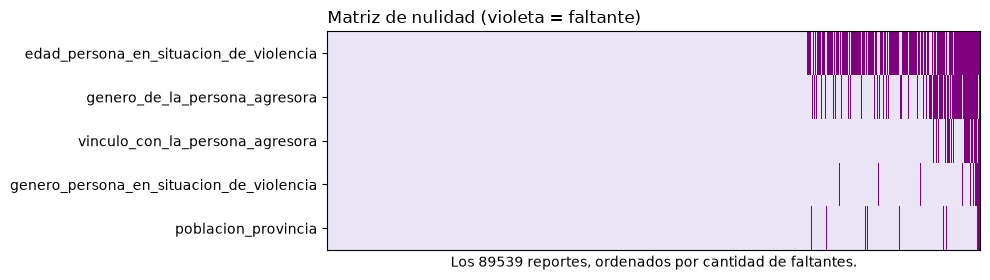

In [17]:
cols_na = faltan[faltan.faltantes > 0].index.tolist()
nulos = df[cols_na].isna()
orden = nulos.sum(axis=1).sort_values(kind="stable").index

fig, ax = plt.subplots(figsize=(10, 2.9))
ax.imshow(nulos.loc[orden].T.astype(int), aspect="auto", interpolation="nearest",
          cmap=plt.matplotlib.colors.ListedColormap(["#e9e5f4", 'purple']))
ax.set_yticks(range(len(cols_na)), cols_na)
ax.set_xticks([])
ax.set_xlabel("Los 89539 reportes, ordenados por cantidad de faltantes.")
ax.set_title("Matriz de nulidad (violeta = faltante)", loc="left")
ax.grid(False)
plt.tight_layout()

### **Imputación en `poblacion_provincia`**

Como fue mencionado anteriormente, la variable `poblacion_provincia` esta vinculado o depende directamente de `prov_persona_en_situacion_violencia`, donde al tener el registro de la provincia donde vive la victima, puede otorgar la cantidad de residentes.

Pero dentro de la primera hay **1312 registros nulos**, mientras que en la segunda no muestra nulos, sino, **1312 registros** con el valor **"sin datos"**, entonces, por consecuente, en el campo `poblacion_provincia`, serán imputados con el número **-1** en los registros que contengan nulos para marcar que en ese registro, no existe registro sobre la provincia donde reside la victima.

In [18]:
# Cantidad de nulos y tipo de dato antes de la imputación
print("--- ANTES ---")
print(f'Cantidad de nulos: {df['poblacion_provincia'].isnull().sum()}')
print(f'Tipo de dato antes: {df['poblacion_provincia'].dtype}')

df['poblacion_provincia'] = pd.to_numeric(df['poblacion_provincia'], errors='coerce').fillna(-1).astype('int64')

# Cantidad de nulos y tipo de dato después de la imputación
print("\n--- DESPUÉS ---")
print(f'Cantidad de nulos: {df['poblacion_provincia'].isnull().sum()}')
print(f'Tipo de dato ahora: {df['poblacion_provincia'].dtype}')

--- ANTES ---
Cantidad de nulos: 1312
Tipo de dato antes: str

--- DESPUÉS ---
Cantidad de nulos: 0
Tipo de dato ahora: int64


Luego de haber tratado `poblacion_provincia`, se volvera a examinar las variables con faltantes y la correlación entre ellas.

### **¿MCAR, MAR o MNAR?**

Las restantes variables con faltantes son categóricas y una continua. Para un tratamiento más adecuado, se analiza el mótivo de la ausencia en esas variables.

Columnas restantes con faltantes: ['edad_persona_en_situacion_de_violencia', 'genero_de_la_persona_agresora', 'vinculo_con_la_persona_agresora', 'genero_persona_en_situacion_de_violencia']


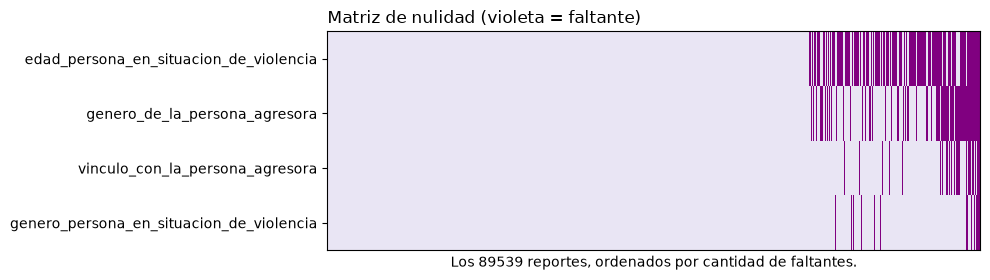

In [19]:
# Muestra en que filas hay faltantes en las columnas a examinar
cols_na = faltan[faltan.faltantes > 0].index.tolist()

# Eliminar 'poblacion_provincia' de la lista cols_na si existe en ella
if 'poblacion_provincia' in cols_na:
    cols_na.remove('poblacion_provincia')
print("Columnas restantes con faltantes:", cols_na)

nulos = df[cols_na].isna()
orden = nulos.sum(axis=1).sort_values(kind="stable").index

fig, ax = plt.subplots(figsize=(10, 2.9))
ax.imshow(nulos.loc[orden].T.astype(int), aspect="auto", interpolation="nearest",
          cmap=plt.matplotlib.colors.ListedColormap(["#e9e5f4", 'purple']))
ax.set_yticks(range(len(cols_na)), cols_na)
ax.set_xticks([])
ax.set_xlabel("Los 89539 reportes, ordenados por cantidad de faltantes.")
ax.set_title("Matriz de nulidad (violeta = faltante)", loc="left")
ax.grid(False)
plt.tight_layout()

<Axes: >

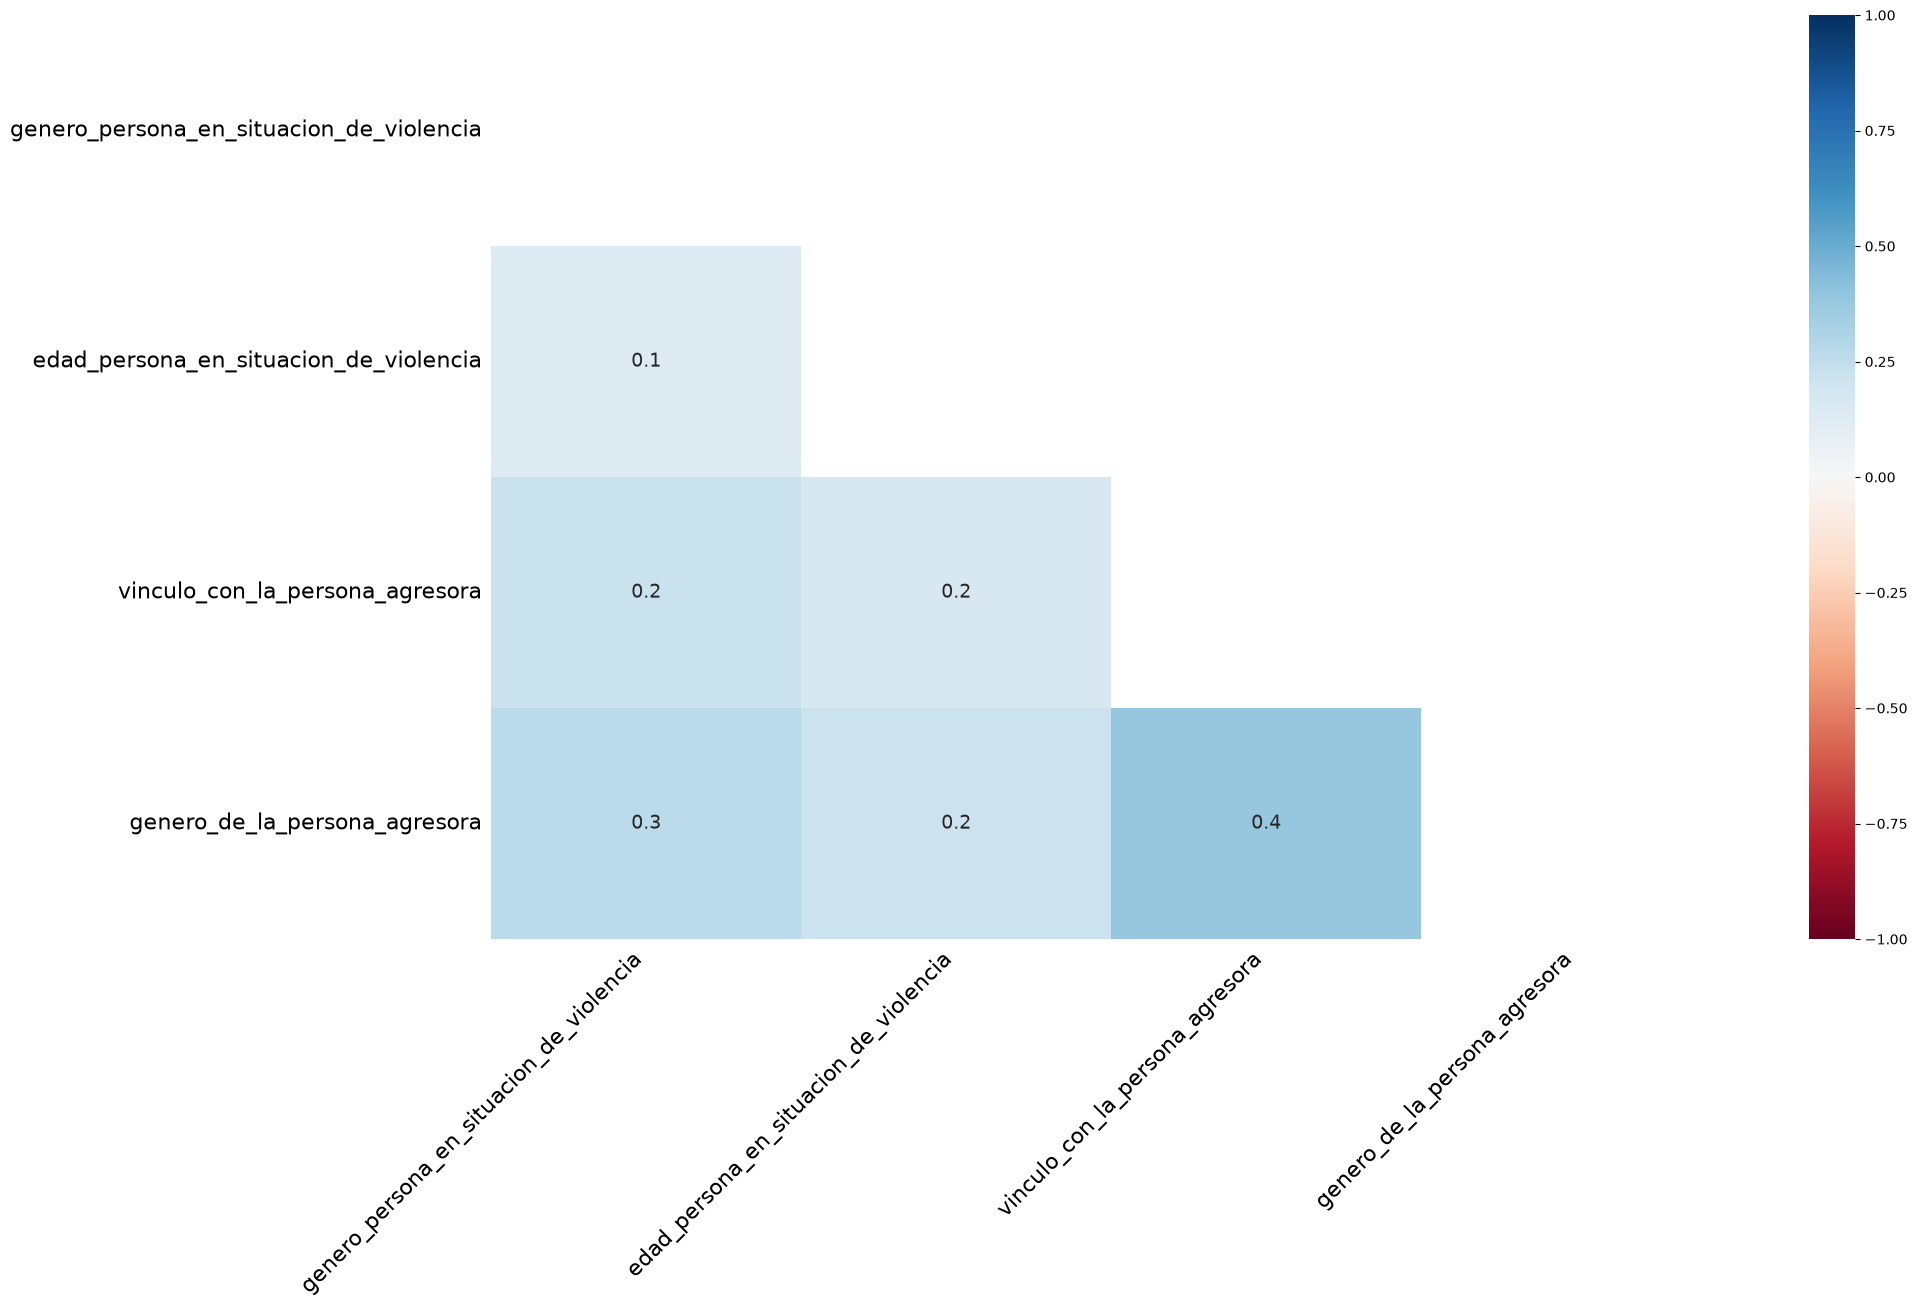

In [20]:
# Muestra un mapa de calor de los campos con faltantes
msno.heatmap(df)

`genero_de_la_persona_agresora` y `vinculo_con_la_persona_agresora` tienden a faltar un poco juntas (correlación de nulidad de 0.4) y los patrones de fila muestrán más bloques al final de los registros.

`genero_de_la_persona_agresora` y `genero_persona_en_situacion_de_violencia` también tienden a faltar un poco juntas (correlación de nulidad de 0.3).

Puede ser esto un indicio de MAR debido a que durante la llamada de emergencia, la prioridad es asistir a la víctima, y por eso no se termina de revelar todos los datos necesarios, también puede ser que el operador no los registró.

---

**Aunque hay un problema para estas variables categóricas**, al querer imputar por estimación, los modelos pueden empujar a las categorías mayoritarias (sea *"varon"*, *"mujer"*) y más si contienen pocos registros para el resto de géneros. **vinculo_con_la_persona_agresora** tiende a categorías más estabilizadas, pero las variables que indican el género, es al contrario a lo mencionado, si fuera el caso, habría menos importancia en los menores casos que aun así son importantes para el dataset.

Para esto, **se aplicaran dos casos**:
- El primero, será codificar las variables para luego meter cada campo con faltantes a **KNN, MICE y IMPUTACIÓN POR GRUPOS**, y luego, serán evaluados para visualizar cuál recupera mejor la información.
- El segundo, será reemplazar los valores **"NaN"** por **sin datos** o **no especificado** y solo se buscara estimar `edad_persona_en_situacion_de_violencia` al ser de tipo continuo, esto utilizando las mismas técnicas del primero caso, donde al final serán evaluados para comprobar cuál recupero más información.

Después de probar ambos casos, se seleccionara el caso en el cuál haya mayor ganancia de información.



#### **1er Caso: Imputar Todo**

In [21]:
# Se incluyen todas las variables relevantes en la codificación
cols_relevantes = [
      'prov_persona_en_situacion_violencia',
      'genero_persona_en_situacion_de_violencia',
      'edad_persona_en_situacion_de_violencia', 'tipo_de_violencia_fisica',
      'tipo_de_violencia_psicologica', 'tipo_de_violencia_sexual',
      'tipo_de_violencia_economica_y_patrimonial',
      'tipo_de_violencia_simbolica', 'tipo_de_violencia_domestica',
      'modalidad_de_violencia_institucional',
      'modalidad_de_violencia_laboral',
      'modalidad_violencia_contra_libertad_reproductiva',
      'modalidad_de_violencia_obstetrica', 'modalidad_de_violencia_mediatica',
      'modalidad_de_violencia_otras', 'vinculo_con_la_persona_agresora',
      'genero_de_la_persona_agresora', 'poblacion_provincia', 'anio', 'mes',
      'dia']

# Se crea una copia para el experimento.
df_caso1 = df[cols_relevantes].copy()

# Se aplica One-Hot Encoding para las variables relevantes.
df_encoded = pd.get_dummies(df_caso1, dummy_na=True)

La siguiente celdas, se encuentran los códigos con las técnicas:

In [22]:
# Servira para evaluar las técnicas
df_torneo = df_encoded.copy()

# --------------------------------
# TÉCNICA 1: Imputación por Grupos
# --------------------------------

df_grupos = df_torneo.copy()

# Se utilizara 'vinculo_con_la_persona_agresora' por estar relacionado estrechamente con la edad de la persona en situación de
# violencia, y esto para evitar agrupar simultáneamente por todas las variables categóricas donde crearía subgrupos diminutos.
if 'vinculo_con_la_persona_agresora_ex pareja' in df_grupos.columns or 'vinculo_con_la_persona_agresora' in df.columns:
  df_grupos_logica = df.copy()
  df_grupos_logica['edad_persona_en_situacion_de_violencia'] = df_grupos_logica['edad_persona_en_situacion_de_violencia'].fillna(

      # Se utiliza la mediana debido a su robustez ante valores extremos y sesgos, reflejando mejor el centro de los datos.
      df_grupos_logica.groupby(['vinculo_con_la_persona_agresora'])['edad_persona_en_situacion_de_violencia'].transform('median')
  )
print("Técnica 1 (Imputación por Grupos) aplicada.")

Técnica 1 (Imputación por Grupos) aplicada.


Demoró menos de 10 segundos en ejecutarse en colab como de manera local.

In [23]:
# --------------------------------
# TÉCNICA 2: KNN Imputer (Vecinos Cercanos)
# --------------------------------

# Se instancia el imputador usando la cantidad de n_neighbors por defecto
knn_imputer = KNNImputer(n_neighbors=5)

# Se aplica KNN sobre el conjunto de interés
df_knn_imputado = pd.DataFrame(
    knn_imputer.fit_transform(df_torneo),
    columns = df_torneo.columns,
    index   = df_torneo.index
)
print("Técnica 2 (KNN Imputer) aplicada.")

Técnica 2 (KNN Imputer) aplicada.


Demoró aproximadamente 15 minutos en ejecutarse en colab, y de manera local demoró 2 minutos con 2.8 segundos.

In [26]:
# --------------------------------
# TÉCNICA 3: MICE / Imputación Iterativa
# --------------------------------

# Se utilizan un límite de 20 iteraciones para garantizar que el proceso iterativo
# tuviera el margen suficiente para estabilizar los valores imputados.
mice_imputer = IterativeImputer(max_iter=20, random_state=42)

# Se aplica MICE sobre el conjunto de interés
df_mice_imputado = pd.DataFrame(
    mice_imputer.fit_transform(df_torneo),
    columns = df_torneo.columns,
    index   = df_torneo.index
)
print("Técnica 3 (MICE / Iterativa) aplicada.")

Técnica 3 (MICE / Iterativa) aplicada.


Demoró apróximadamente 4 a 5 minutos en ejecutarse en colab, y de manera local demoró 53.1 segundos.

##### **Evaluación de las 3 Técnicas de Imputación**

In [27]:
# Comparación de Edad
print('--- Edad Original ---')
print(df['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por Grupos ---')
print(df_grupos['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por KNN ---')
print(df_knn_imputado['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por MICE ---')
print(df_mice_imputado['edad_persona_en_situacion_de_violencia'].describe().round(2))

--- Edad Original ---
count    72261.00
mean        35.69
std         12.59
min          1.00
25%         27.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por Grupos ---
count    72261.00
mean        35.69
std         12.59
min          1.00
25%         27.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por KNN ---
count    89539.00
mean        35.70
std         11.63
min          1.00
25%         28.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por MICE ---
count    89539.00
mean        35.70
std         11.42
min          1.00
25%         28.00
50%         34.57
75%         41.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64


- La **edad imputada por grupos** se mantuvo en 72261 registros en lugar de 89539, dejando registros vacíos, el mótivo es porque en `edad` como `vinculo_con_la_persona_agresora` tenían faltantes, entonces el método se queda sin categoría para agrupar, y no sabe que mediana asignar, dejando registros vacíos (NaN).

- La **edad imputada por KNN y MICE** lograron rellenar la totalidad de registros, y la media solo la diferencia es de 0.01, aunque, **KNN** conserva la mediana en su lugar, y su desviación (11.63) es más cercana a la original (12.59) que la de **MICE** (11.42), esto se podrá visualizar mejor en la visualización de distribución.

findfont: Failed to find font weight semibold, now using 700.


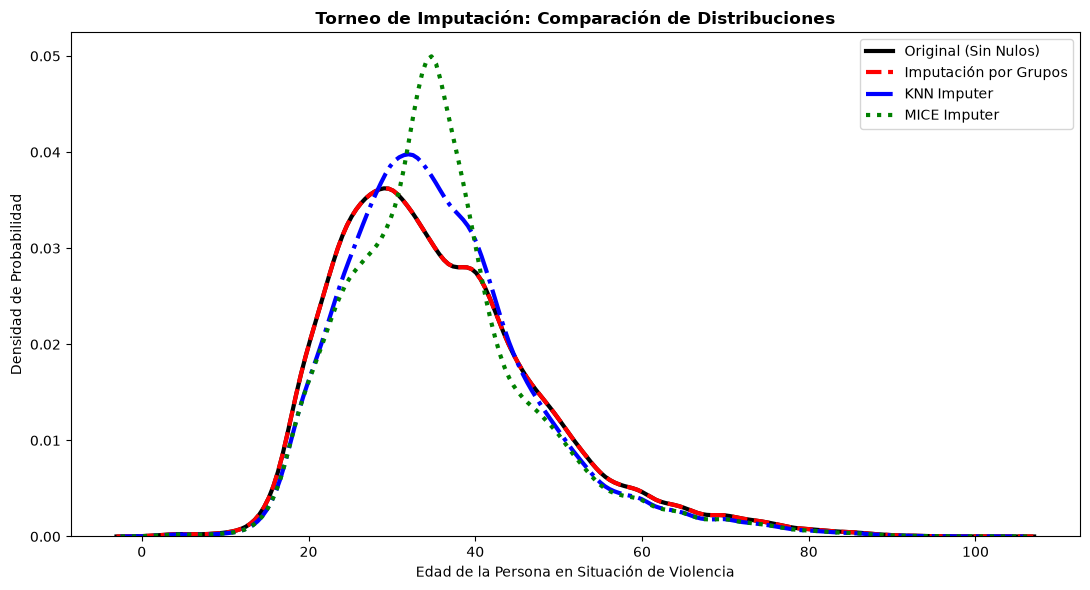

In [28]:
# Comparación Visual (Curvas de Densidad KDE)
plt.figure(figsize=(11, 6))

# Distribución Original (exluyendo nulos) - Color Negro
sns.kdeplot(df['edad_persona_en_situacion_de_violencia'].dropna(),
            label='Original (Sin Nulos)',
            color='black',
            linewidth=3
)

# Distribución con Imputación por Grupos - Color Rojo Vivo
sns.kdeplot(df_grupos['edad_persona_en_situacion_de_violencia'],
            label='Imputación por Grupos',
            color='red',
            linestyle='--',
            linewidth=3,
)

# Distribución con KNN - Color Azul
sns.kdeplot(df_knn_imputado['edad_persona_en_situacion_de_violencia'],
            label='KNN Imputer',
            color='blue',
            linestyle='-.',
            linewidth=3
)

# Distribución con MICE - Color Verde
sns.kdeplot(df_mice_imputado['edad_persona_en_situacion_de_violencia'],
            label='MICE Imputer',
            color='green',
            linestyle=':',
            linewidth=3
)

plt.title('Torneo de Imputación: Comparación de Distribuciones', fontsize=12, fontweight='semibold')
plt.xlabel('Edad de la Persona en Situación de Violencia')
plt.ylabel('Densidad de Probabilidad')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

- La **Imputación por Grupos** preserva con exactitud la distribución, pero no pudo rellenar la totalidad de registros, entonces dependió completamente de la variable.

- **KNN Imputer** aunque se eleva ligeramente la densidad en la zona media, acompaña la silueta y la curvatura del dataset original de forma orgánica.

- **MICE** respeta menos la silueta y se puede ver como hace un pico alto entre los 30 y 40 años, esto debe ser porque concentra la predicción en torno a los valores más probables o esperados, apretando los datos hacia el centro.

##### **Técnica de Imputación Ganadora**
Tras evaluar el torneo de imputación, se selecciona a **KNN Imputer** como la técnica ganadora.

Si bien la **imputación por grupos** preserva con exactitud la distribución, carece de la cantidad total de registros.

Por otro lado, aunque **MICE** ofrece estimaciones robustas, genera una concentración o pico de densidad, que reduce la varianza general de los datos.

**KNNImputer** logra el mejor balance, con la totalidad del dataset imputados (89.539 registros), preserva de manera óptima el desvío estándar original y mantiene una curva de densidad (KDE) fiel a la distribución real de las edades.

#### **2do Caso: Imputar Solo en Edad**

In [29]:
# Copia del trabajo del Dataframe original.
df_caso2 = df.copy()

# Lista de las variables que serán rellenados con 'sin datos'.
cols_categ_rellenar = [
    'genero_persona_en_situacion_de_violencia',
    'vinculo_con_la_persona_agresora',
    'genero_de_la_persona_agresora'
]

# Rellenado de 'sin datos' en las variables categóricas con faltantes.
for col in cols_categ_rellenar:
  if col in df_caso2.columns:
    df_caso2[col] = df_caso2[col].fillna('sin datos')

# Seleccionado de columnas para el modelo
cols_relevantes2 = [
      'prov_persona_en_situacion_violencia',
      'genero_persona_en_situacion_de_violencia',
      'edad_persona_en_situacion_de_violencia', 'tipo_de_violencia_fisica',
      'tipo_de_violencia_psicologica', 'tipo_de_violencia_sexual',
      'tipo_de_violencia_economica_y_patrimonial',
      'tipo_de_violencia_simbolica', 'tipo_de_violencia_domestica',
      'modalidad_de_violencia_institucional',
      'modalidad_de_violencia_laboral',
      'modalidad_violencia_contra_libertad_reproductiva',
      'modalidad_de_violencia_obstetrica', 'modalidad_de_violencia_mediatica',
      'modalidad_de_violencia_otras', 'vinculo_con_la_persona_agresora',
      'genero_de_la_persona_agresora', 'poblacion_provincia', 'anio', 'mes',
      'dia']

df_sub_caso2 = df_caso2[cols_relevantes2].copy()

# Se aplica One-Hot Encoding
# Como no hay NaN en las categóricas, ponemos dummy_na=False
df_encoded_caso2 = pd.get_dummies(df_sub_caso2, dummy_na=False)

La siguiente celdas, se encuentran los códigos con las técnicas:

In [30]:
# --------------------------------
# TÉCNICA 1: Imputación por Grupos
# --------------------------------

df_grupos_caso2 = df_encoded_caso2.copy()
df_grupos_caso2['edad_persona_en_situacion_de_violencia'] = df_grupos_caso2['edad_persona_en_situacion_de_violencia'].fillna(
    df_grupos_caso2.groupby(['vinculo_con_la_persona_agresora_sin datos'])['edad_persona_en_situacion_de_violencia'].transform('median')
)
print("Técnica 1 (Imputación por Grupos) aplicada.")

Técnica 1 (Imputación por Grupos) aplicada.


Fue ejecutado al instante en colab, como de manera local.

In [31]:
# --------------------------------
# TÉCNICA 2: KNN Imputer (Vecinos Cercanos)
# --------------------------------

knn_imputer = KNNImputer(n_neighbors=5)

df_knn_caso2 = pd.DataFrame(
    knn_imputer.fit_transform(df_encoded_caso2),
    columns = df_encoded_caso2.columns,
    index   = df_encoded_caso2.index
)
print("Técnica 2 (KNN Imputer) aplicada.")

Técnica 2 (KNN Imputer) aplicada.


Demoró aproximadamente 13 minutos en ejecutarse en colab, y de manera local demoró 1 minuto con 46.5 segundos.

In [32]:
# --------------------------------
# TÉCNICA 3: MICE / Imputación Iterativa
# --------------------------------

mice_imputer = IterativeImputer(max_iter=20, random_state=42)

df_mice_caso2 = pd.DataFrame(
    mice_imputer.fit_transform(df_encoded_caso2),
    columns = df_encoded_caso2.columns,
    index   = df_encoded_caso2.index
)
print("Técnica 3 (MICE / Iterativa) aplicada.")

Técnica 3 (MICE / Iterativa) aplicada.


Demoró aproximadamente 4 minutos en ejecutarse en colab, y de manera local demoró 38.8 segundos.

##### **Evaluación de las 3 Técnicas de Imputación**

In [33]:
# Comparación de Edad (CASO 2)
print('--- Edad Original ---')
print(df['edad_persona_en_situacion_de_violencia'].dropna().describe().round(2))

print('\n--- Edad Imputada por Grupos ---')
print(df_grupos_caso2['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por KNN ---')
print(df_knn_caso2['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por MICE ---')
print(df_mice_caso2['edad_persona_en_situacion_de_violencia'].describe().round(2))

--- Edad Original ---
count    72261.00
mean        35.69
std         12.59
min          1.00
25%         27.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por Grupos ---
count    89539.00
mean        35.34
std         11.34
min          1.00
25%         28.00
50%         34.00
75%         40.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por KNN ---
count    89539.00
mean        35.70
std         11.63
min          1.00
25%         28.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por MICE ---
count    89539.00
mean        35.70
std         11.42
min          1.00
25%         28.00
50%         34.57
75%         41.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64


- Las tres técnicas lograron rellenar con exito en todo el campo.

- **KNN** como **MICE** mantuvieron una media más cercana al original (una diferencia de 0.01), mientras que la desviación de KNN (11.63) es más cercana a la original (12.59) que **MICE** (11.41) y **Imputación por Grupos** (11.34).

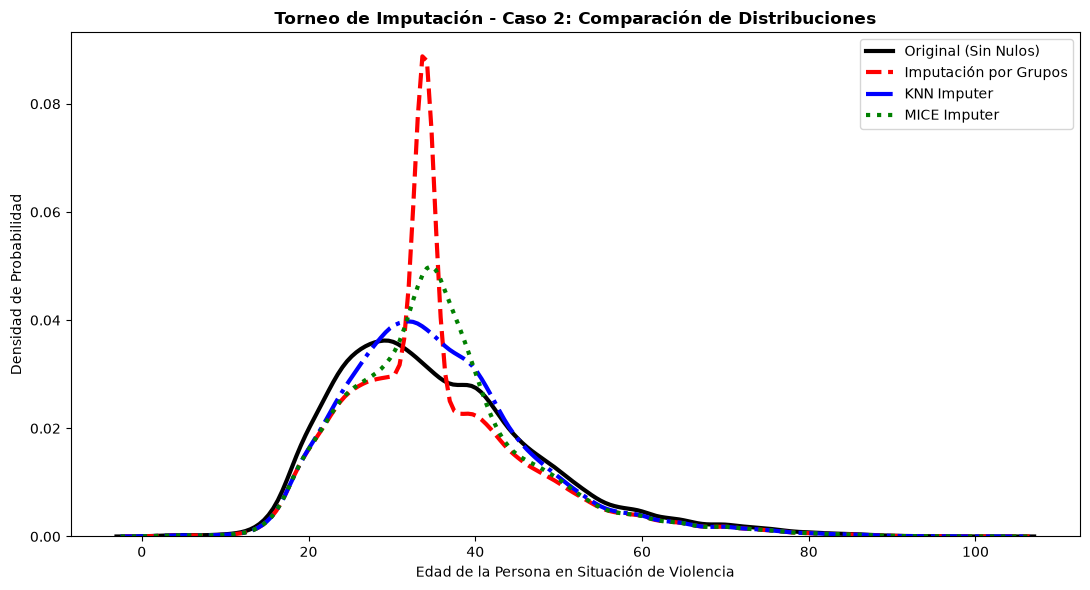

In [34]:
# Comparación Visual (Curvas de Densidad KDE) - (CASO 2)
plt.figure(figsize=(11, 6))

# Distribución Original (exluyendo nulos) - Color Negro
sns.kdeplot(df['edad_persona_en_situacion_de_violencia'].dropna(),
            label='Original (Sin Nulos)',
            color='black',
            linewidth=3
)

# Distribución con Imputación por Grupos - Color Rojo Vivo
sns.kdeplot(df_grupos_caso2['edad_persona_en_situacion_de_violencia'],
            label='Imputación por Grupos',
            color='red',
            linestyle='--',
            linewidth=3,
)

# Distribución con KNN - Color Azul
sns.kdeplot(df_knn_caso2['edad_persona_en_situacion_de_violencia'],
            label='KNN Imputer',
            color='blue',
            linestyle='-.',
            linewidth=3
)

# Distribución con MICE - Color Verde
sns.kdeplot(df_mice_caso2['edad_persona_en_situacion_de_violencia'],
            label='MICE Imputer',
            color='green',
            linestyle=':',
            linewidth=3
)

plt.title('Torneo de Imputación - Caso 2: Comparación de Distribuciones', fontsize=12, fontweight='semibold')
plt.xlabel('Edad de la Persona en Situación de Violencia')
plt.ylabel('Densidad de Probabilidad')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

- La **Imputación por Grupos** al ser rellenado con 'sin datos', presenta un pico gigante entre los 30 y 35 años, una gran masa de datos o edad cayó dentro del mismo grupo, deformando la distribución real.

- **KNN Imputer** aunque se eleva ligeramente la densidad en la zona media, respeta mucho la silueta y la curvatura del dataset original de forma orgánica, evitando picos absurdos.

- **MICE** respeta menos la silueta, pero puede que sea más contenido el rango del pico alto entre los 35 y 40 años en esta ocasión, y esto debe ser porque la categoría 'sin datos' aportara información clara al modelo.

##### **Técnica de Imputación Ganadora (Caso 2)**
Tras evaluar el 2do torneo de imputación, se selecciona nuevamente a **KNN Imputer** como la técnica ganadora.

Si bien, las tres técnicas contienen la cantidad total de registros, la **Imputación por Grupos** presenta un gran pico en el rango de 30 y 40 años, mientras que **MICE** aunque el rango sea más chico, sigue concentrado los datos en la parte mayoritaría de los registros.

**KNNImputer** logra preservar de manera óptima la distribución real de las edades como mantener de manera óptima el desvío estandar original.

#### **Torneo: KNN (Caso 1) vs KNN (Caso 2)**

In [35]:
# Comparación de Edad (CASO 2)
print('--- Edad Original ---')
print(df['edad_persona_en_situacion_de_violencia'].dropna().describe().round(2))

print('\n--- Edad Imputada por KNN - Caso 1 ---')
print(df_knn_imputado['edad_persona_en_situacion_de_violencia'].describe().round(2))

print('\n--- Edad Imputada por KNN - Caso 2 ---')
print(df_knn_caso2['edad_persona_en_situacion_de_violencia'].describe().round(2))

--- Edad Original ---
count    72261.00
mean        35.69
std         12.59
min          1.00
25%         27.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por KNN - Caso 1 ---
count    89539.00
mean        35.70
std         11.63
min          1.00
25%         28.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64

--- Edad Imputada por KNN - Caso 2 ---
count    89539.00
mean        35.70
std         11.63
min          1.00
25%         28.00
50%         34.00
75%         42.00
max        103.00
Name: edad_persona_en_situacion_de_violencia, dtype: float64


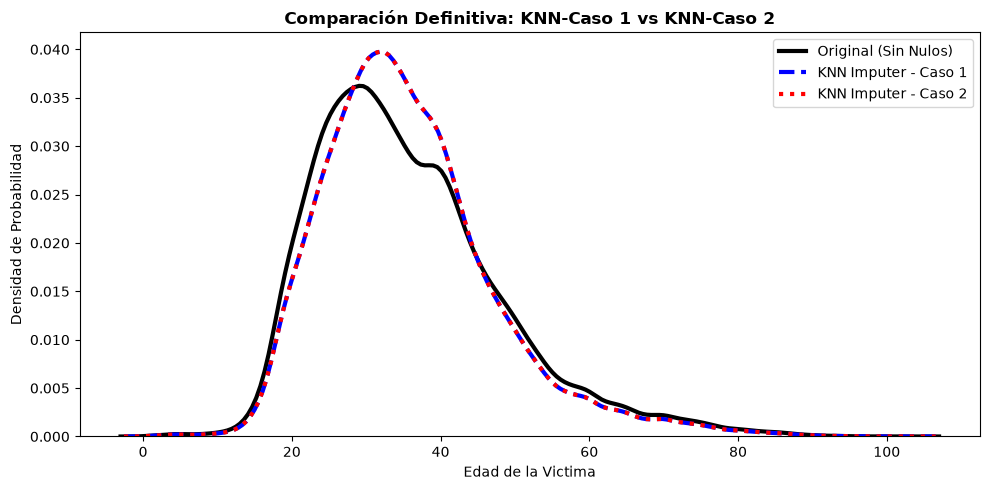

In [36]:
plt.figure(figsize=(10, 5))
# Realidad
sns.kdeplot(df['edad_persona_en_situacion_de_violencia'].dropna(),
            label='Original (Sin Nulos)',
            color='black',
            linewidth=3
)

# KNN - Caso 1
sns.kdeplot(df_knn_imputado['edad_persona_en_situacion_de_violencia'],
            label='KNN Imputer - Caso 1',
            color='blue',
            linestyle='--',
            linewidth=3
)

# KNN - Caso 2
sns.kdeplot(df_knn_caso2['edad_persona_en_situacion_de_violencia'],
            label='KNN Imputer - Caso 2',
            color='red',
            linestyle=':',
            linewidth=3
)

plt.title('Comparación Definitiva: KNN-Caso 1 vs KNN-Caso 2', fontsize=12, fontweight='semibold')
plt.xlabel('Edad de la Victima')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.tight_layout()
plt.show()

Dado que a nivel de distribución numérica empatan o están prácticamente calcadas, ambos logran capturar el contexto de edad de forma excelente, por lo tanto, la decisión final se puede inclinar por cualquier caso, en esta ocasión, el **Caso 1**, debido a que preserva la estructura original de los nulos mediante la gestión automática de *dummy_na=True*, y prepara mejor la matriz para el entrenamiento del modelo en un formato más limpio y robusto, ideal para los algoritmos de Machine Learning para que puedan interpretar las ausencias como variables binarias independientes sin contaminar las categorías reales.

#### **Oficializar la Técnica y Caso Ganador**

In [37]:
# Se guarda el resultado del KNN - Caso 1 en una variable oficial de trabajo
df_procesado = df_knn_imputado.copy()

# Verificación de Dimensión
print(f'Dimensión de la matriz procesada: {df_procesado.shape}')

# Verificación de nulos
nulos_restantes = df_procesado.isna().sum().sum()
print(f'Celdas nulas restantes: {nulos_restantes}')

Dimensión de la matriz procesada: (89539, 96)
Celdas nulas restantes: 0


### **Feature Engineering**

- Calcular tasa de reportes con población

- Eliminar columnas _no y _nan, sino hay multicolinealidad

- Indicar fin de semana

- ordenar por fecha

- Estabilizar edad de victima y poblacion_provincia con StandardScaled o RobustScaler

- Decidir Modelo si clasificación o no supervisado. Si es no supervisado, tener cuidado con la dimensionalidad, en la materia ciencia de datos esta PCA para arreglar esto.

#### **Enriquecimiento y Ordenado por Fecha**

In [38]:
# Se vuelve agregar la columna 'Fecha' en el 'df_procesado' para poder extraer si fue fin de semana.
df_procesado['Fecha'] = pd.to_datetime(
    df_procesado[['anio', 'mes', 'dia']].rename(columns={'anio': 'year', 'mes': 'month', 'dia': 'day'})
)

# Se agrega una columna para indicar si fue fin de semana
df_procesado['is_weekend'] = (df_procesado['Fecha'].dt.dayofweek >= 5).astype(int)

# Se ordena el DataFrame por fecha
df_procesado = df_procesado.sort_values(by='Fecha').reset_index(drop=True)

# Luego de haber hecho estas operaciones, se elimina definitivamente el campo 'Fecha'
df_procesado = df_procesado.drop(columns=['Fecha'])

#### **Creación de Scores e Interacciones**

Para poder categorizar si el riesgo del reporte es "Alto" o "Medio", se basara en un sistema de puntaje llamado 'Score'.

Esta se basa en la confirmación del tipo o modalidad de violencia, en la que dependiendo cuál haya sido confirmada, habrá una suma (o también, una suma de peso), y si el puntaje total de la suma (o también si algún tipo o modalidad en especial fue seleccionada) llega a alcanzar cierto puntaje, será reportado de "Riesgo Alto", caso contrario, solo será clasificado como "Riesgo Medio".

In [39]:
# Score Exponencial de Tipos de Violencia
# La violencia física y sexual tienen un peso mayor que a las demás.
df_procesado['score_tipos_violencia'] = (
    df_procesado['tipo_de_violencia_fisica_si'] * 4 +
    df_procesado['tipo_de_violencia_sexual_si'] * 4 +
    df_procesado['tipo_de_violencia_psicologica_si'] * 1 +
    df_procesado['tipo_de_violencia_economica_y_patrimonial_si'] * 1 +
    df_procesado['tipo_de_violencia_simbolica_si'] * 1
)

# Score de Modalidades / Ámbitos Críticos
# El ámbito doméstico e institucional/laboral tendrán mayor peso por asimetría de poder.
df_procesado['score_modalidades_criticas'] = (
    df_procesado['tipo_de_violencia_domestica_si'] * 3 +
    df_procesado['modalidad_de_violencia_institucional_si'] * 2 +
    df_procesado['modalidad_de_violencia_laboral_si'] * 2
)

# Interacción de Gravedad Doméstica
# Multiplica la severidad del daño físico/sexual por la vulnerabilidad de que ocurra en el hogar.
df_procesado['interaccion_gravedad_domestica'] = (
    df_procesado['score_tipos_violencia'] * df_procesado['tipo_de_violencia_domestica_si']
)

# Vínculo de Alto Riesgo
# Suma las opciones de pareja y ex-pareja, que estadísticamente concentran mayor letalidad.
df_procesado['vinculo_alto_riesgo'] = (
    df_procesado['vinculo_con_la_persona_agresora_pareja'] + 
    df_procesado['vinculo_con_la_persona_agresora_ex pareja']
)

# Se verifica que se hayan creado correctamente
print("Columnas de scores creadas con éxito:")
print(df_procesado[['score_tipos_violencia', 'score_modalidades_criticas', 
                    'interaccion_gravedad_domestica', 'vinculo_alto_riesgo']].head())

Columnas de scores creadas con éxito:
   score_tipos_violencia  score_modalidades_criticas  \
0                    6.0                         3.0   
1                    7.0                         3.0   
2                    6.0                         3.0   
3                    6.0                         3.0   
4                    6.0                         3.0   

   interaccion_gravedad_domestica  vinculo_alto_riesgo  
0                             6.0                  1.0  
1                             7.0                  1.0  
2                             6.0                  1.0  
3                             6.0                  1.0  
4                             6.0                  1.0  


Esto servira para evitar que una acumulación de violencias leves empate con un golpe físico o abuso sexual gracias a los pesos exponenciales (multiplicar por 4). Además, por `interaccion_gravedad_domestica` genera un valor numérico muy alto para aquellos casos graves dentro de la casa, facilitando la tarea de separar el **Riesgo Alto** con el **Medio**.

#### **Limpieza y Filtrado de Columnas**

Se quitaran las columnas que terminen en `_no` o `_nan` serán eliminados.

Mientras que `_no` son una "duplicación inversa" de las de `_si`, introduciendo a la multicolinealidad, mientras que las columnas `_nan`, le enseñarían al modelo a agrupar a las personas por "falta de datos en el formulario", generando ruido, en lugar de hacerlo por su nivel de riesgo real.

Esto también permitira reducir la cantidad de columnas que actualmente hay en el DataFrame procesado.

In [40]:
# Se identifican las columnas que terminan en '_no' o contienen '_nan'.
columnas_a_eliminar = [
    col for col in df_procesado.columns
    if col.endswith('_no') or '_nan' in col
]

# Se eliminan las columnas identificadas del DataFrame procesado.
df_procesado = df_procesado.drop(columns=columnas_a_eliminar)

# Se verifica el resultado.
print(f'Se eliminaron {len(columnas_a_eliminar)} columnas.')
print(f'Nueva dimensión en el DataFrame procesado: {df_procesado.shape}')

Se eliminaron 28 columnas.
Nueva dimensión en el DataFrame procesado: (89539, 73)


Las columnas con provincias permanecenar intactas, no serán utilizadas durante el entrenamiento, pero si será utilizada para por ejemplo, extraer qué provincia se concentra el mayor porcentaje de casos de "Riesgo Alto".

#### **Escalado de Variables Numéricas Continuas**

Se aplicara StandardScaler sobre las variables numéricas y los nuevos scores (como la edad, la población y los puntajes creados) para que todos queden con la misma escala.

In [41]:
# Se define la matriz 'X' con las variables numéricas y scores que si iran al modelo
# (Se exluyen las provincias en One-Hot y cualquier otra columna categórica o de texto)
features_modelado = [
    'edad_persona_en_situacion_de_violencia',
    'poblacion_provincia',
    'score_tipos_violencia',
    'score_modalidades_criticas',
    'interaccion_gravedad_domestica',
    'vinculo_alto_riesgo',
    'is_weekend'
]

# Se crea la matriz 'X', y ase asegura de rellenar cualquier NaN con la mediana.
X = df_procesado[features_modelado].fillna(df_procesado[features_modelado].median())

# Se aplicamos el StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dimensiones de la matriz: {X_scaled.shape}")

Dimensiones de la matriz: (89539, 7)


#### **Reducción de Dimensionalidad (PCA)**

Se aplicara PCA para comprimir los atributos escalados (`X_scaled`), la cuál contiene 7 variables numéricas y de dominio seleccionados (edad, población provincial, scores de violencia, interacciones y vínculos).

Se buscara la cantidad de componentes necesarios hasta acumular al menos el 85% de la información (varianza) de los datos.

In [42]:
# Indicamos que retenga los componentes necesarios para explicar el 85% de la varianza total.
pca = PCA(n_components=0.85, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print('--- Resultados de PCA ---')
print(f'Dimensiones antes de PCA: {X_scaled.shape}')
print(f'Dimensiones después de PCA: {X_pca.shape}')
print(f'Varianza explicada acumulada: {pca.explained_variance_ratio_.sum() * 100:.2f}%')

--- Resultados de PCA ---
Dimensiones antes de PCA: (89539, 7)
Dimensiones después de PCA: (89539, 5)
Varianza explicada acumulada: 92.06%


- La matriz pasó de tener **7 variables originales** a un espacio reducido de **5 componentes principales (`X_pca`)**, manteniendo intactas las 89.539 instancias del dataset procesado.

- Se alcanzó un **92.06%** de Varianza Explicada Acumulada, sin perder información crítica, superando con éxito el umbral mínimo del 85% establecido.

In [43]:
# Mostrar la varianza explicada por cada componente
print("Varianza explicada por componente:", pca.explained_variance_ratio_)

print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por componente: [0.32822528 0.17202424 0.14451745 0.14227159 0.13361083]
Varianza explicada acumulada: 0.920649393303092


- El componente 1 (**PC1** con apróximadamente 32.8%) es el eje principal que concentra la mayor cantidad de variabilidad (probablemente contenga el score de violencia y la interacción doméstica)

- Los restantes componentes de 2 a 5 (13% a 17%) distribuyen la información de manera equilibrada entre edad, población provincial, vínculos y fines de semana.

Esto desmuestra que con solo 5 dimensiones se puede retener más del 90% de toda la información real del dataset, evitando la pérdida de datos críticos.

##### **Visualización de la Varianza Explicada Acumulada**

Para respaldar el análisis numérico de forma gráfica, se mostrara la **curva de varianza explicada acumulada**.

Esta visualización permite inspeccionar cómo se acumula la información a medida que incorporamos cada componente principal, facilitando la validación del umbral de corte seleccionado

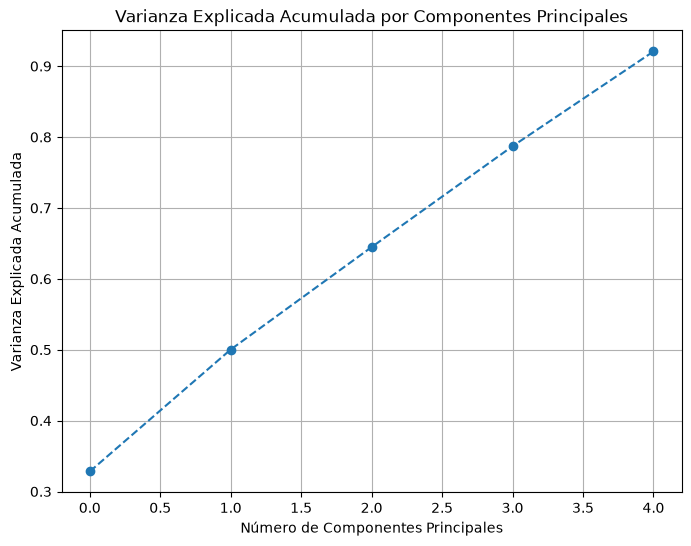

In [44]:
# Varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_

# Varianza explicada acumulada
cumulative_explained_variance = np.cumsum(explained_variance)

# Graficar varianza explicada acumulada
plt.figure(figsize=(8, 6))
plt.plot(cumulative_explained_variance, marker='o', linestyle='--')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid()
plt.show()

A partir de la visualización obtenida, se puede destacar lo siguiente:
- La línea muestra un ascenso constante a lo largo de los **5 componentes**, mostrando que ninguna acapara toda la información de forma abrupta, sino que el contenido se distribuye de forma equilibrada.

- Al final de la línea, la curva cruza la marca del 90% en el eje Y, alcanzando el **92.06%** de varianza acumulada. Esto demuestra que esta cantidad límite de componentes retiene la señal real de los datos sin arrastrar ruido innecesario.

##### **Proyección Bidimensional y Validación del Espacio Latente**

Se proyectan los datos en un plano de 2 dimensiones, utilizando los dos primeros componentes principales (**PC1** y **PC2**).

Como no se cuenta con una etiqueta de clase predefinidad, se utilizara temporalmente el **Score de Tipos de Violencia** como una variable de contraste (color), permitiendo evaluar de forma cualitativa si los ejes principales capturan efectivamente la severidad y el nivel de riesgo de los reportes.

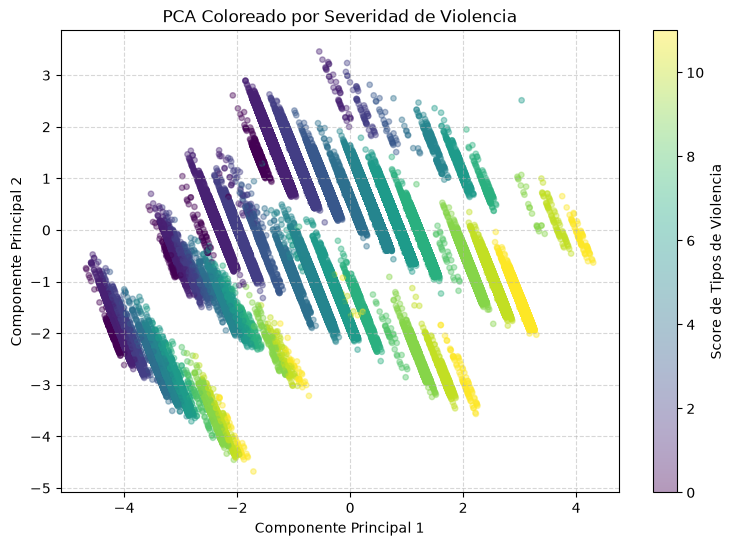

In [45]:
df_pca = pd.DataFrame(X_pca[:, 0:2], columns=['PC1', 'PC2'])
# Usamos tu score de tipos de violencia como 'target' visual temporal
df_pca['score_violencia'] = df_procesado['score_tipos_violencia']

plt.figure(figsize=(9, 6))
scatter = plt.scatter(df_pca['PC1'], df_pca['PC2'], 
                      c=df_pca['score_violencia'], cmap='viridis', alpha=0.4, s=15)
plt.colorbar(scatter, label='Score de Tipos de Violencia')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('PCA Coloreado por Severidad de Violencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

A partir del gráfico de dipsersión obtenido, se destaca lo siguiente:
- **Estructura en Franjas (Patrón Tabular):** La formación de líneas diagonales paralelas responde a la combinación de las variables originales y los scores. Miles de casos que comparten perfiles similares se agrupan en coordenadas geométricas exactas dentro del espacio.

- **Gradiente de Severidad:** Se observa una progresión visual de los colores (desde los tonos morados en la zona superior-izquierda, hasta los amarillos brillantes en la inferior-derecha). Esto demuestra que **el PC1 y el PC2 separan, de manera natural, los casos de menor complejidad de aquellos con alta severidad**

### **Persistencia del Dataset Procesado**

Para finalizar el pipeline de preparación de datos, se guardara el DataFrame procesado en formato **Parquet**.

El mótivo de este es porque almacenara de manera nativa los esquemas y tipos de datos, además que optimiza el espacio en disco, acelerando el tiempo de lectura y escritura.

In [ ]:
# Se guarda el DataFrame completo (con los scores, variables limpias y provincias de respaldo)
df_procesado.to_parquet('dataset_procesado.parquet', index=False)

print(f"Dimensiones finales persistidas: {df_procesado.shape}")

Dimensiones finales persistidas: (89539, 73)


## **Conclusión**

- **Corrección de Anomalias y Manejo de Valores Extremos:** Se identificaron y filtraron errores tipográficos (como el registro aislado de una edad de '127 años'), preservando al mismo tiempo casos reales pero atípicos (como reportes en rangos de edad de 1 a 10 años realizados por terceros).

- **Optimización y Reducción de Variables Redundantes:** Se eliminaron columnas innecesarias o problemáticas para evitar problemas, como la multicolinealidad con la columna `Año` por ya tener `Fecha`, y el país de nacimiento de la víctima, el cual contaba con una alta tasa de valores nulos (~33.8%) y escasa relevancia para determinar el nivel de riesgo de los reportes.

- **Estandarización Formal y Unificación Semántica:** Se normalizaron las variables categóricas mediante la conversión a minúsculas y la eliminación de acentos en campos clave como provincias, géneros, tipos y modalidades de violencia, y vínculo entre victima y agresor.

- **Gestión Rigurosa de Valores Faltantes:** Si bien el volumen global de celdas vacías era bajo (apróximadamente un 1.7%), se prestó atención a variables con mayor proporción de nulos (como la edad de la víctima con un 19.3%). Se implementaron imputaciones estratégicas, como el uso de un valor centinela ('-1') para mantener la trazabilidad de los registros faltantes en la población provincial sin distorsionar la distribución natural de los datos.

- **Estructuración Temporal:** La correcta conversión de la variable `Fecha` a formato `datetime` y su posterior descomposición en `anio`, `mes` y `dia` facilita la futura ingeniería de atributos temporales (como estacionalidades o patrones de comportamiento según el día de la semana).

El dataset se encuentra curado, estandarizado y optimizado. Se redujo significativamente el ruido y sesgo potencial por inconsistencias de carga, dejando la base de datos en optimas condiciones para empezar la siguiente etapa con el entrenamiento de los modelos no supervisados.